# BloodMNIST | Shared preparation for Parts A and B

**Goal.** Set up a common dataset, preprocessing, classical baseline, and evaluation protocol for eight-class blood cell classification.

Run this notebook from top to bottom in Google Colab with a CPU runtime. Part A will compare a custom CNN with and without augmentation. Part B will compare frozen and fine-tuned ResNet-18. Both parts use the same official split membership and report the same metrics.

[Official MedMNIST dataset and documentation](https://medmnist.com/)

## 1. Install the dataset package and import libraries

Colab provides NumPy, pandas, Matplotlib, and scikit-learn. Install MedMNIST to load the official splits.

In [1]:
%pip install -q medmnist

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from medmnist import BloodMNIST, INFO
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from threadpoolctl import threadpool_limits

SEED = 42
IMAGE_SIZE = 128
DATA_ROOT = Path("data")
DATA_ROOT.mkdir(exist_ok=True)

## 2. Dataset Loading and Verification

We load the official BloodMNIST training, validation, and test splits. For each split, we verify the number of images, RGB image dimensions, and class labels.

- **Training split** is used to fit the models and calculate normalization statistics.
- **Validation split** is used to compare settings and select model checkpoints.
- **Test split** is used to report final performance after model settings are fixed.

In [3]:
info = INFO["bloodmnist"]
class_ids = sorted(int(label) for label in info["label"])
class_names = [info["label"][str(label)] for label in class_ids]
NUM_CLASSES = len(class_names)

assert NUM_CLASSES == 8
assert class_ids == list(range(NUM_CLASSES))

datasets = {
    split: BloodMNIST(split=split, root=str(DATA_ROOT), size=IMAGE_SIZE, download=True)
    for split in ("train", "val", "test")
}
images = {split: dataset.imgs for split, dataset in datasets.items()}
labels = {split: dataset.labels.reshape(-1) for split, dataset in datasets.items()}

split_summary = []
for split, split_images in images.items():
    expected_count = info["n_samples"][split]
    assert split_images.shape == (expected_count, IMAGE_SIZE, IMAGE_SIZE, 3), split
    assert split_images.dtype == np.uint8, split
    assert labels[split].shape == (expected_count,), split
    assert np.issubdtype(labels[split].dtype, np.integer), split
    assert np.array_equal(np.unique(labels[split]), class_ids), split

    split_summary.append({
        "Split": split,
        "Images": expected_count,
        "Image shape (H, W, C)": split_images.shape[1:],
        "Classes": len(np.unique(labels[split])),
    })

display(pd.DataFrame(split_summary).set_index("Split"))
display(pd.Series(class_names, index=class_ids, name="Blood cell class").rename_axis("Class ID"))

100%|██████████| 569M/569M [04:24<00:00, 2.15MB/s]


,Images,"Image shape (H, W, C)",Classes
Split,,,
train,11959,"(128, 128, 3)",8
val,1712,"(128, 128, 3)",8
test,3421,"(128, 128, 3)",8


,Blood cell class
Class ID,
0,basophil
1,eosinophil
2,erythroblast
3,"immature granulocytes(myelocytes, metamyelocyt..."
4,lymphocyte
5,monocyte
6,neutrophil
7,platelet


## 3. Exploratory Data Analysis and Class Visualization

We display three randomly selected training images from each of the eight blood cell classes. These examples help us inspect variation in cell shape, color, and nucleus appearance within and across classes.

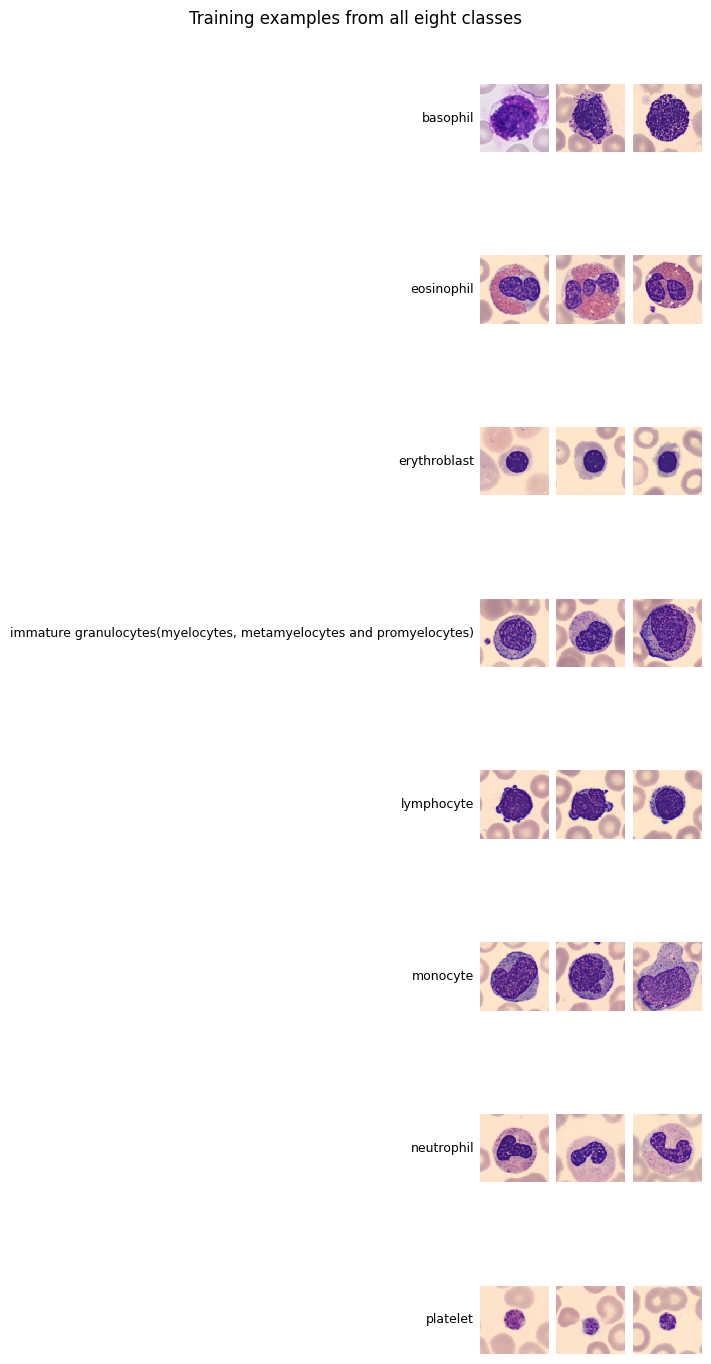

In [4]:
rng = np.random.default_rng(SEED)
examples_per_class = 3
fig, axes = plt.subplots(NUM_CLASSES, examples_per_class, figsize=(7, 14), layout="constrained")

for row, (class_id, name) in enumerate(zip(class_ids, class_names)):
    candidates = np.flatnonzero(labels["train"] == class_id)
    indices = rng.choice(candidates, size=examples_per_class, replace=False)
    for column, image_index in enumerate(indices):
        ax = axes[row, column]
        ax.imshow(images["train"][image_index], interpolation="nearest")
        ax.set_xticks([])
        ax.set_yticks([])
        if column == 0:
            ax.set_ylabel(name, rotation=0, ha="right", va="center", fontsize=9)
        for spine in ax.spines.values():
            spine.set_visible(False)

fig.suptitle("Training examples from all eight classes")
plt.show()

## 4. Class Distribution Analysis

We calculate the count and percentage of images belonging to each class in the training, validation, and test splits. Percentages make it easier to compare class distributions across splits with different numbers of images.

We report macro F1 alongside accuracy because macro F1 gives each class equal weight, regardless of how many images it contains.

,train,val,test
Class,,,
basophil,852,122,244
eosinophil,2181,312,624
erythroblast,1085,155,311
"immature granulocytes(myelocytes, metamyelocytes and promyelocytes)",2026,290,579
lymphocyte,849,122,243
monocyte,993,143,284
neutrophil,2330,333,666
platelet,1643,235,470


,train,val,test
Class,,,
basophil,7.1,7.1,7.1
eosinophil,18.2,18.2,18.2
erythroblast,9.1,9.1,9.1
"immature granulocytes(myelocytes, metamyelocytes and promyelocytes)",16.9,16.9,16.9
lymphocyte,7.1,7.1,7.1
monocyte,8.3,8.4,8.3
neutrophil,19.5,19.5,19.5
platelet,13.7,13.7,13.7


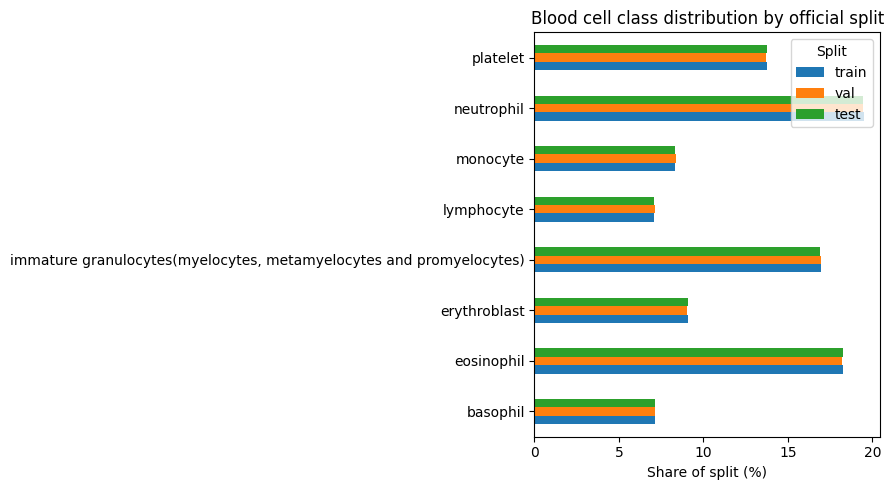

In [5]:
class_counts = pd.DataFrame(
    {split: np.bincount(targets, minlength=NUM_CLASSES) for split, targets in labels.items()},
    index=pd.Index(class_names, name="Class"),
)
class_percentages = class_counts.div(class_counts.sum(axis=0), axis=1) * 100
display(class_counts)
display(class_percentages.round(1))

ax = class_percentages.plot.barh(figsize=(9, 5))
ax.set_xlabel("Share of split (%)")
ax.set_ylabel("")
ax.set_title("Blood cell class distribution by official split")
ax.legend(title="Split")
plt.tight_layout()
plt.show()

## 5. Image Preprocessing and Normalization

We scale RGB pixel values from `[0, 255]` to `[0, 1]`. We then calculate a mean and standard deviation for each RGB channel using only the training images.

The classical baseline and Part A use these BloodMNIST normalization statistics. In Part A, any training augmentation is applied before normalization. Part B uses the normalization associated with the ImageNet-pretrained weights and applies the same evaluation preprocessing to both ResNet-18 configurations.

In [6]:
train_pixels = images["train"].astype(np.float32) / 255.0
rgb_mean = train_pixels.mean(axis=(0, 1, 2), dtype=np.float64).astype(np.float32)
rgb_std = train_pixels.std(axis=(0, 1, 2), dtype=np.float64).astype(np.float32)
del train_pixels

assert (rgb_std > 0).all()

display(pd.DataFrame({"Mean": rgb_mean, "Std": rgb_std}, index=["Red", "Green", "Blue"]))

def normalized_images(split_images):
    # Scale and normalize an array of RGB images in (N, H, W, C) order.
    scaled = split_images.astype(np.float32) / 255.0
    return (scaled - rgb_mean) / rgb_std

# def flattened_features(split):
#     # Return one row of normalized RGB pixel features per image.
#     return normalized_images(images[split]).reshape(len(labels[split]), -1)

def flattened_features(split):
    # Downsample 128×128 to 32×32 by averaging each 4×4 pixel block.
    split_images = images[split]
    n_images = len(split_images)
    small_images = split_images.reshape(n_images, 32, 4, 32, 4, 3).mean(
        axis=(2, 4), dtype=np.float32
    )
    return normalized_images(small_images).reshape(n_images, -1)

def bloodmnist_normalize_transform():
    # Return the torchvision normalization step for Part A, after ToTensor.
    from torchvision import transforms

    return transforms.Normalize(mean=rgb_mean.tolist(), std=rgb_std.tolist())

,Mean,Std
Red,0.796043,0.225779
Green,0.659605,0.258646
Blue,0.696358,0.095721


## 6. Common Evaluation Metrics

We use a shared evaluation function to compare predictions against the true class labels.

- **Accuracy** measures the proportion of correctly classified images.
- **Macro F1** averages the F1 scores of the eight classes equally.
- **Balanced accuracy** averages recall across the classes.
- **Per-class metrics** report precision, recall, F1, and the number of examples in each class.
- **Confusion matrices** show which classes the models commonly confuse.

In [7]:
def evaluate_predictions(y_true, y_pred, model_name, split, *, show_details=True):
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)

    if y_true.shape != y_pred.shape:
        raise ValueError("Provide one predicted class ID per true label.")
    if not np.isin(y_true, class_ids).all() or not np.isin(y_pred, class_ids).all():
        raise ValueError("Labels and predictions must be valid class IDs.")

    results = {
        "Model": model_name,
        "Split": split,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro F1": f1_score(y_true, y_pred, labels=class_ids, average="macro", zero_division=0),
        "Balanced accuracy": balanced_accuracy_score(y_true, y_pred),
    }

    if show_details:
        report = classification_report(
            y_true, y_pred, labels=class_ids, target_names=class_names,
            zero_division=0, output_dict=True,
        )
        display(pd.DataFrame(report).T.loc[class_names].round(3))

        matrix = confusion_matrix(y_true, y_pred, labels=class_ids)
        fig, ax = plt.subplots(figsize=(9, 7), layout="constrained")
        ConfusionMatrixDisplay(matrix, display_labels=class_names).plot(
            ax=ax, cmap="Blues", values_format="d", xticks_rotation=45,
            colorbar=False,
        )
        ax.set_title(f"{model_name} | {split}")
        plt.show()

    return results

## 7. Classical Machine Learning Baseline

We train a logistic regression model on flattened, normalized RGB pixel features from the training split. This model provides a shared classical reference for the two deep-learning experiments.

We also fit a majority-class classifier as a sanity check. It predicts the most frequent training class for every image.

In [11]:
X_train = flattened_features("train")
X_val = flattened_features("val")
y_train = labels["train"]
y_val = labels["val"]

baseline = LogisticRegression(solver="lbfgs", C=1.0, max_iter=3000)
with threadpool_limits(limits=2, user_api="blas"):
    baseline.fit(X_train, y_train)

majority = DummyClassifier(strategy="most_frequent")
majority.fit(X_train, y_train)

DummyClassifier(strategy='most_frequent')

## 8. Baseline Evaluation on the Validation Split

We evaluate logistic regression and the majority-class classifier on the official validation split. We compare their accuracy, macro F1, and balanced accuracy.

The logistic regression confusion matrix shows which classes are commonly confused. Rows represent the true classes, and columns represent the predicted classes.

,precision,recall,f1-score,support
basophil,0.670,0.582,0.623,122.0
eosinophil,0.939,0.939,0.939,312.0
erythroblast,0.885,0.845,0.865,155.0
"immature granulocytes(myelocytes, metamyelocytes and promyelocytes)",0.679,0.672,0.676,290.0
lymphocyte,0.836,0.877,0.856,122.0
monocyte,0.658,0.741,0.697,143.0
neutrophil,0.877,0.877,0.877,333.0
platelet,0.987,0.996,0.992,235.0


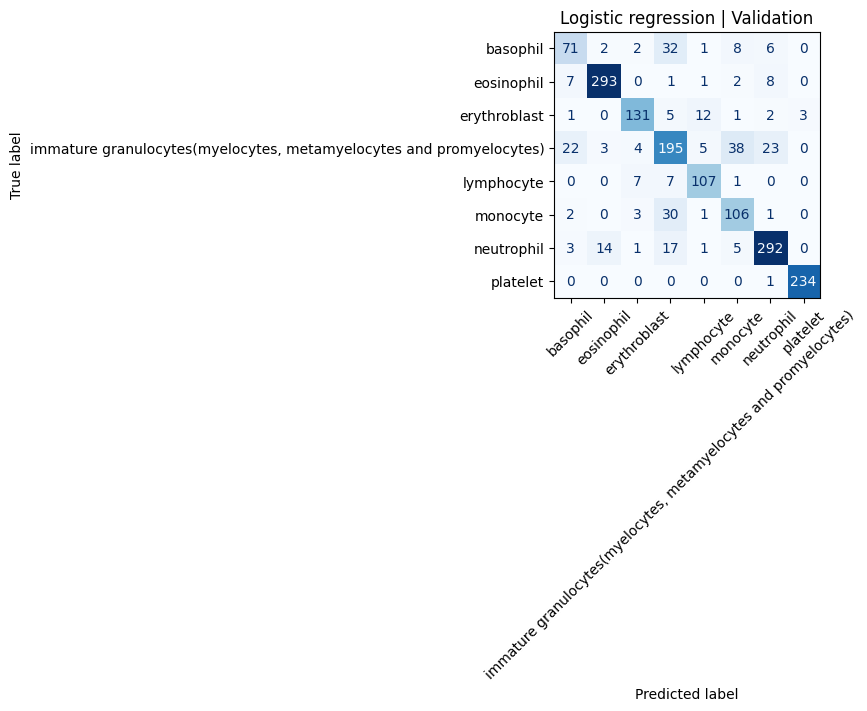

,Model,Split,Accuracy,Macro F1,Balanced accuracy
0,Majority class,Validation,0.1945,0.0407,0.1250
1,Logistic regression,Validation,0.8347,0.8155,0.8162


In [12]:
val_results = [
    evaluate_predictions(
        y_val, majority.predict(X_val), "Majority class", "Validation", show_details=False
    ),
    evaluate_predictions(
        y_val, baseline.predict(X_val), "Logistic regression", "Validation"
    ),
]
display(pd.DataFrame(val_results).round(4))

## 9. Final Evaluation on the Test Split

After the settings and checkpoints for Parts A and B have been selected using validation results, we evaluate the classical baseline on the official test split. Set `RUN_FINAL_TEST = True` to run this cell.

Both deep-learning experiments use the same official test split and evaluation metrics so their results can be reported alongside the classical baseline.

,precision,recall,f1-score,support
basophil,0.659,0.627,0.643,244.0
eosinophil,0.936,0.921,0.929,624.0
erythroblast,0.859,0.865,0.862,311.0
"immature granulocytes(myelocytes, metamyelocytes and promyelocytes)",0.646,0.655,0.650,579.0
lymphocyte,0.863,0.831,0.847,243.0
monocyte,0.664,0.697,0.680,284.0
neutrophil,0.858,0.862,0.860,666.0
platelet,0.992,1.000,0.996,470.0


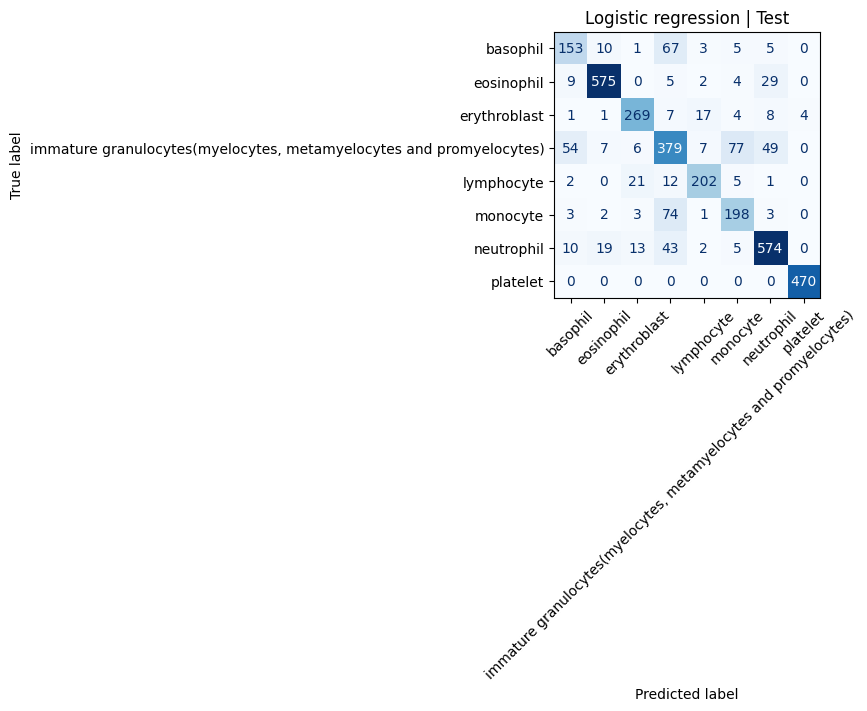

,Model,Split,Accuracy,Macro F1,Balanced accuracy
0,Logistic regression,Test,0.8243,0.8084,0.8073


In [13]:
RUN_FINAL_TEST = True

if RUN_FINAL_TEST:
    X_test = flattened_features("test")
    y_test = labels["test"]
    test_results = [
        evaluate_predictions(
            y_test, baseline.predict(X_test), "Logistic regression", "Test"
        ),
    ]
    display(pd.DataFrame(test_results).round(4))